# Workshop 3

In [237]:
# Import libraries
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
from scipy import optimize
from scipy.stats import norm
from iminuit import cost, Minuit

# Set a random seed for reproducibility
RANDOM_SEED = 42

In [238]:
# Load in data
data_exp = np.loadtxt("datafile-exp.txt")
data_exp_gaus = np.loadtxt("datafile-expgaus.txt")

### First, for the exponential data

Plot the data without any best fit lines first.

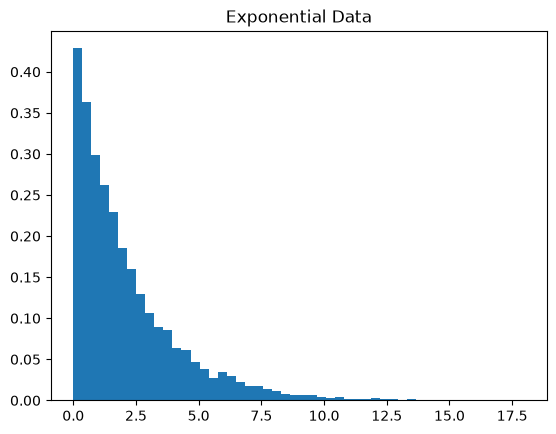

In [239]:
# Plot the data and normalise the histogram to have a total area of 1
plt.hist(data_exp, bins = 50, label='Exponential', density = True)
plt.title("Exponential Data")
plt.show()

Define function to fit the data. 

In [240]:
# Exponential function
def exp_func(x, slope_exp):
    return scipy.stats.expon.pdf(x, scale = slope_exp)

migrad = finds the local minimum such as a chi^2 or log-likelihood function.
hesse = computes the covariance / error matrix.

In [241]:
# Define an unbinned NLL
cost_exp = cost.UnbinnedNLL(data_exp, exp_func)

# First estimate of exponential decay parameter
slope_exp = np.mean(data_exp)

# Run the fit
m_exp = Minuit(cost_exp, slope_exp)
m_exp.migrad()
m_exp.hesse()

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.532e+04                  │              Nfcn = 20               │
│ EDM = 2.46e-17 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name      │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼───────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ slope_exp │   2.150   │   0.021   │            │            │         │         │       │
└───┴───────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌───────────┬───────────┐
│           │ slope_exp │
├───────────┼───────────┤
│ slope_exp │  0.000462 │
└───────────┴───────────┘

In [242]:
# Obtain the results
m_exp_value = m_exp.values[0]

# Print out results
print(m_exp)
print(m_exp_value)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.532e+04                  │              Nfcn = 20               │
│ EDM = 2.46e-17 (Goal: 0.0002)    │                                      │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬───────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬─

Plot the graphs with the best fit line.

In [243]:
# Create an x-array
x_min_exp = min(data_exp)
x_max_exp = max(data_exp)
x_array = np.linspace(x_min_exp, x_max_exp, 100)

# Obtain data using the best fit parameter
#best_fit_exp = exp_func(x_array, slope_exp)
best_fit_exp = exp_func(x_array, m_exp_value)

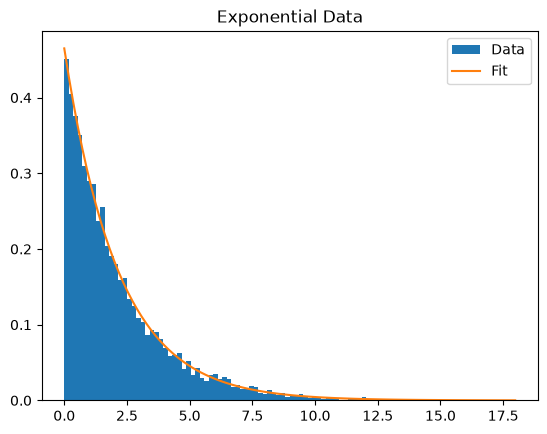

In [244]:
# Plot the data and normalise the histogram to have a total area of 1
plt.hist(data_exp, bins = 100, label = "Data", density = True)
plt.plot(x_array, best_fit_exp, label = "Fit")
plt.title("Exponential Data")
plt.legend()
plt.show()

Plot the covariance.

### Now for the exponential gaussian data

Plot the data without any best fit lines first.

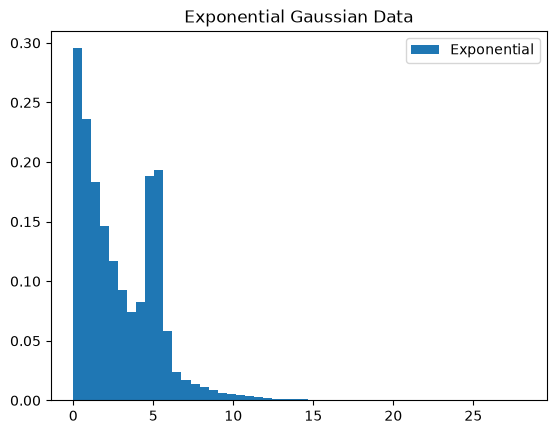

In [245]:
# Plot the data and normalise the histogram to have a total area of 1
plt.hist(data_exp_gaus, bins = 50, label='Exponential', density = True)
plt.title("Exponential Gaussian Data")
plt.legend()
plt.show()

Define function to fit the data.

In [246]:
# Gaussian function
def exp_gaus_func(x, frac_exp, slope_exp, mean_gauss, width_gauss):

    exp = scipy.stats.expon.pdf(x, scale = slope_exp)
    gauss = scipy.stats.norm.pdf(x, loc = mean_gauss, scale = width_gauss)

    return frac_exp * exp + (1 - frac_exp) * gauss

In [247]:
# Define an unbinned NLL
cost_exp_gauss = cost.UnbinnedNLL(data_exp_gaus, exp_gaus_func)

# First estimate of exponential gaussian parameters
# [slope_exp, mean_gauss]
# Use best fit exp m from last dataset
frac_exp = 0.5
slope_exp = m_exp_value
mean_gauss = 5
width_gauss = 0.4
exp_gauss_args = slope_exp, mean_gauss, width_gauss

# Run the fit
exp_gauss_vals = Minuit(cost_exp_gauss, frac_exp, slope_exp, mean_gauss, width_gauss)
exp_gauss_vals.fixed["width_gauss"] = True # Fix the value of the width
exp_gauss_vals.limits["frac_exp"] = (0, 1)
exp_gauss_vals.migrad()
exp_gauss_vals.hesse()

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.883e+05                  │              Nfcn = 79               │
│ EDM = 1.95e-06 (Goal: 0.0002)    │            time = 0.7 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────┬───────┐
│   │ Name        │   Value   │ Hesse Err │ Minos Err- │ Minos Err+ │ Limit-  │ Limit+  │ Fixed │
├───┼─────────────┼───────────┼───────────┼────────────┼────────────┼─────────┼─────────┼───────┤
│ 0 │ frac_exp    │  0.7991   │  0.0016   │            │            │    0    │    1    │       │
│ 1 │ slope_exp   │   2.397   │   0.009   │            │            │         │         │       │
│ 2 │ mean_gauss  │   5.099   │   0.004   │            │            │         │         │       │
│ 3 │ width_gauss │   0.400   │   0.004   │            │            │         │         │  yes  │
└───┴─────────────┴───────────┴───────────┴────────────┴────────────┴─────────┴─────────┴───────┘
┌─────────────┬─────────────────────────────────────────────────┐
│             │    frac_exp   slope_exp  mean_gauss width_gauss │
├─────────────┼─────────────────────────────────────────────────┤
│    frac_exp │    2.49e-06      2.9e-6      0.4e-6           0 │
│   slope_exp │      2.9e-6    8.18e-05   -0.001e-3           0 │
│  mean_gauss │      0.4e-6   -0.001e-3    1.48e-05           0 │
│ width_gauss │           0           0           0           0 │
└─────────────┴─────────────────────────────────────────────────┘

In [248]:
# Obtain the results
frac_exp = exp_gauss_vals.values[0]
slope_exp_value = exp_gauss_vals.values[1]
mean_gauss_value = exp_gauss_vals.values[2]

# Print out results
print(exp_gauss_vals)
print(frac_exp)
print(slope_exp_value)
print(mean_gauss_value)

┌─────────────────────────────────────────────────────────────────────────┐
│                                Migrad                                   │
├──────────────────────────────────┬──────────────────────────────────────┤
│ FCN = 3.883e+05                  │              Nfcn = 79               │
│ EDM = 1.95e-06 (Goal: 0.0002)    │            time = 0.7 sec            │
├──────────────────────────────────┼──────────────────────────────────────┤
│          Valid Minimum           │   Below EDM threshold (goal x 10)    │
├──────────────────────────────────┼──────────────────────────────────────┤
│      No parameters at limit      │           Below call limit           │
├──────────────────────────────────┼──────────────────────────────────────┤
│             Hesse ok             │         Covariance accurate          │
└──────────────────────────────────┴──────────────────────────────────────┘
┌───┬─────────────┬───────────┬───────────┬────────────┬────────────┬─────────┬─────────

Plot graphs with the best fit lines.

In [249]:
# Create an x-array
x_min_exp_gaus = min(data_exp_gaus)
x_max_exp_gaus = max(data_exp_gaus)
x_array = np.linspace(x_min_exp_gaus, x_max_exp_gaus, 100)

# Obtain data using the best fit parameter
best_fit_exp_gaus = exp_gaus_func(x_array, frac_exp, slope_exp_value, mean_gauss_value, width_gauss)

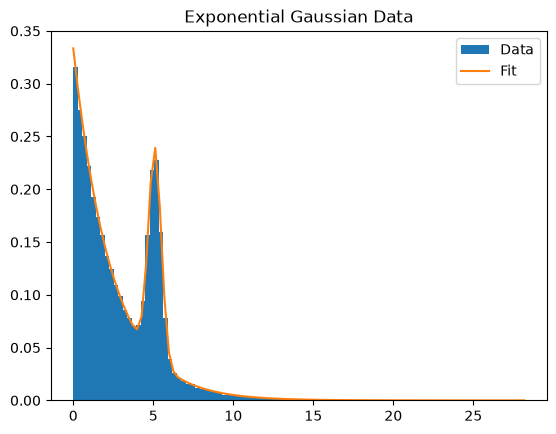

In [250]:
# Plot the data and normalise the histogram to have a total area of 1
plt.hist(data_exp_gaus, bins = 100, label = "Data", density = True)
plt.plot(x_array, best_fit_exp_gaus, label = "Fit")
plt.title("Exponential Gaussian Data")
plt.legend()
plt.show()

In [257]:
# Get the covariance matrix
exp_gauss_vals.covariance

,frac_exp,slope_exp,mean_gauss,width_gauss
frac_exp,2.49e-06,2.9e-6 (0.203),0.4e-6 (0.059),0
slope_exp,2.9e-6 (0.203),8.18e-05,-0.001e-3 (-0.014),0
mean_gauss,0.4e-6 (0.059),-0.001e-3 (-0.014),1.48e-05,0
width_gauss,0,0,0,0


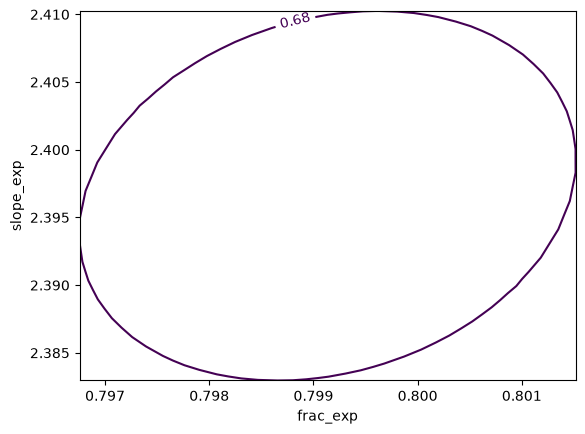

In [254]:
# Plot the covariance
exp_gauss_vals.draw_mncontour("frac_exp", "slope_exp")

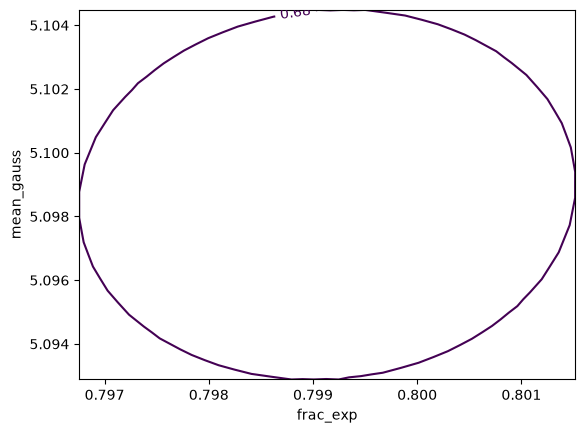

In [255]:
exp_gauss_vals.draw_mncontour("frac_exp", "mean_gauss")

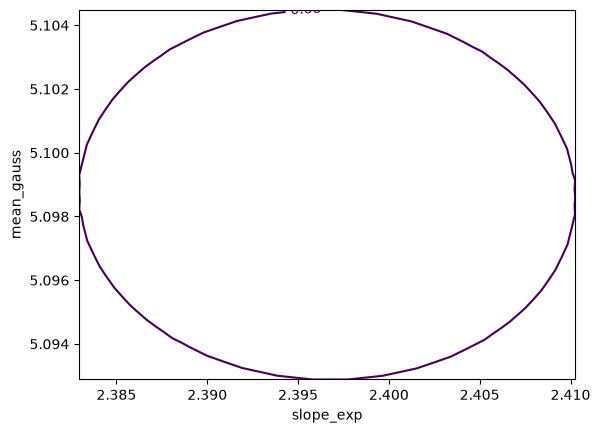

In [256]:
exp_gauss_vals.draw_mncontour("slope_exp", "mean_gauss")